In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from taia1dvfd.analysis import compute_forecast_score_phi, get_model_variable, kp_metrics

In [2]:
OUTPUT_FOLDER = "/home/mnex/Desktop/1DV_FD/experiments/1_Kato_Phillips/output"
CLOSURES = {'k-kl':      r'$k\text{-}kl$',
          'k-epsilon': r'$k\text{-}\epsilon$',
          'k-omega':   r'$k\text{-}\omega$',
          'gen':       r'$gen$',
          'tke':       r'$TKE$'}
NZ_VALUES = [512, 128, 32]
DT_VALUES = [36, 360, 3600]

# Kato - Phillips Experiment 

In this idealized configuration, the mixed‑layer depth is expected to follow an empirical deepening law of the form

$$\mathrm{MLD}(t) = 1.05\,\frac{u_*}{\sqrt{N}}\,\sqrt{t - t_0}$$

Reliable for about 30h

In [3]:
def plot_grid(draw_func, ylabel = r"MLD $[m]$", title = None):
    fig, axes = plt.subplots(len(NZ_VALUES), len(DT_VALUES), figsize=(int(len(NZ_VALUES)*3 + 2), int(len(DT_VALUES)*2 + 1)),sharex=True, squeeze=False)
    fig.suptitle(title)
    for i, nz in enumerate(NZ_VALUES):
        for j, dt in enumerate(DT_VALUES):
            ax = axes[i, j]
            
            for key in CLOSURES:
                draw_func(ax, key, dt, nz)

            ax.grid(True, alpha=0.4)
            if j == 0:
                ax.set_ylabel(ylabel)
            if i == len(NZ_VALUES) - 1:
                ax.set_xlabel(r'$t$ [$h$]')

    for j, dt in enumerate(DT_VALUES):
        axes[0, j].annotate(rf'$\Delta t = {dt}\,$s', xy=(0.5, 1.1), xycoords='axes fraction', va='center', ha='center', fontsize=12, 
                            bbox=dict(boxstyle='round', facecolor='peachpuff',edgecolor='0.7'))

    for i, nz in enumerate(NZ_VALUES):
        axes[i, -1].annotate(rf'$n_z = {nz}$', xy=(1.045, 0.5), xycoords='axes fraction', va='center', ha='left', fontsize=12,
                                bbox=dict(boxstyle='round', facecolor='lemonchiffon', edgecolor='0.7'))

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    
def ref_MLD(t):
    N2 = np.sqrt(1e-4)
    ust = 0.01
    return -1.05 * ust/np.sqrt(N2) * np.sqrt(t)

## Deterministic case

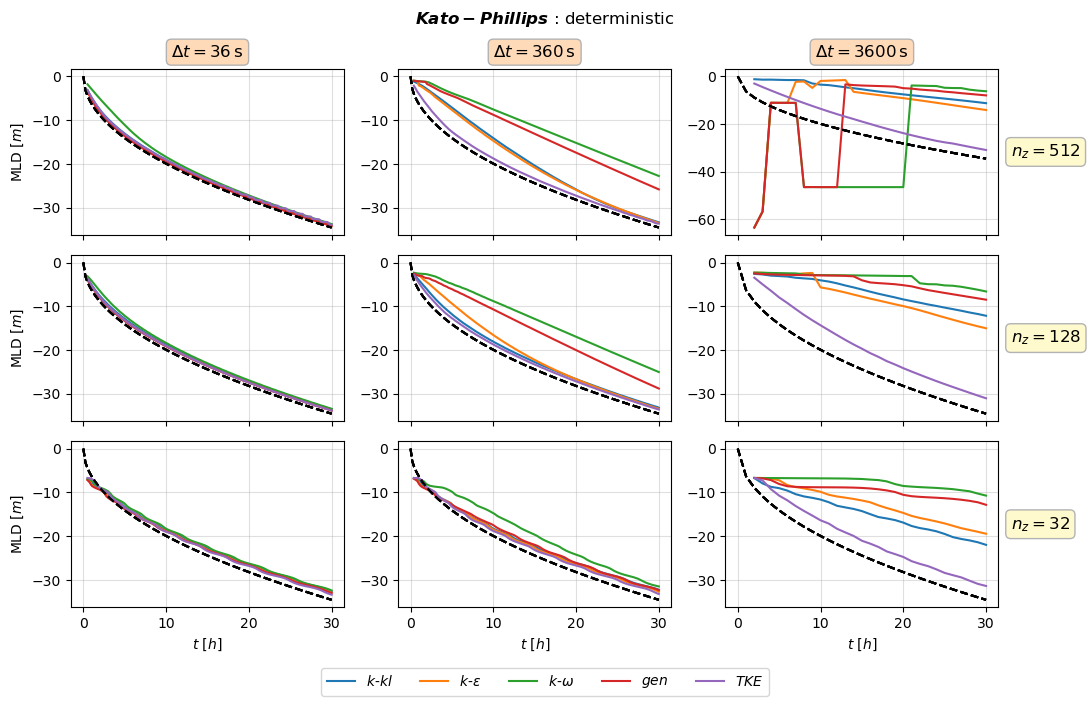

In [4]:
def draw_mld_det(ax, key, dt, nz):
    # --- Draw closure ---
    _, t, mld_m, _ = get_model_variable(f"{OUTPUT_FOLDER}/deterministic/{key}_dt{dt}_nz{nz}_ne1.nc", "mld")
    t /= 3600
    line, = ax.plot(t[2:], -mld_m[2:], label=CLOSURES[key])

    # --- Draw reference ---
    mld = ref_MLD(t*3600)
    ax.plot(t, mld, 'k--')

plot_grid(draw_mld_det, title = r"$\boldsymbol{Kato-Phillips}$ : deterministic")

## Stochastic case

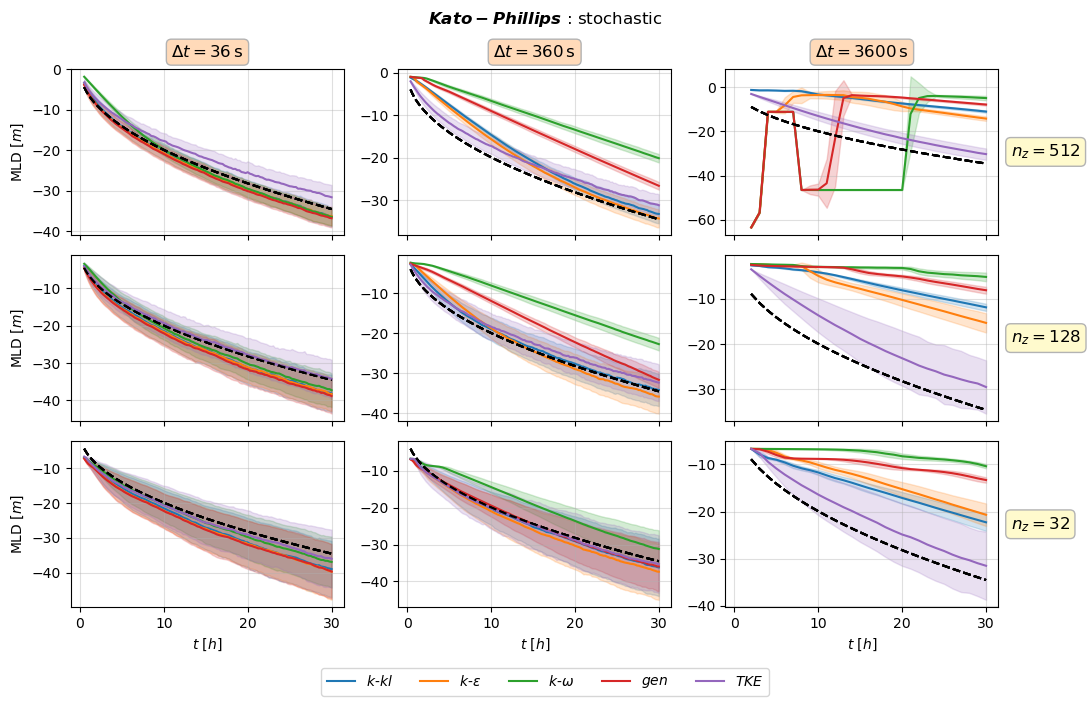

In [5]:
def draw_mld_stoch(ax, key, dt, nz):
    # --- Draw closure ---
    _, t, mld_m, mld_v = get_model_variable(f"{OUTPUT_FOLDER}/stochastic/{key}_dt{dt}_nz{nz}_ne500.nc", "mld")
    t = t[2:]
    mld_m = mld_m[2:]
    mld_v = mld_v[2:]
    
    t /= 3600
    line, = ax.plot(t, -mld_m, label=CLOSURES[key])
    ax.fill_between(t, -(mld_m - mld_v ** 0.5), -(mld_m + mld_v ** 0.5), alpha=0.2, color=line.get_color())

    # --- Draw reference ---
    mld = ref_MLD(t*3600)
    ax.plot(t, mld, 'k--')
    
plot_grid(draw_mld_stoch, title = r"$\boldsymbol{Kato-Phillips}$ : stochastic")

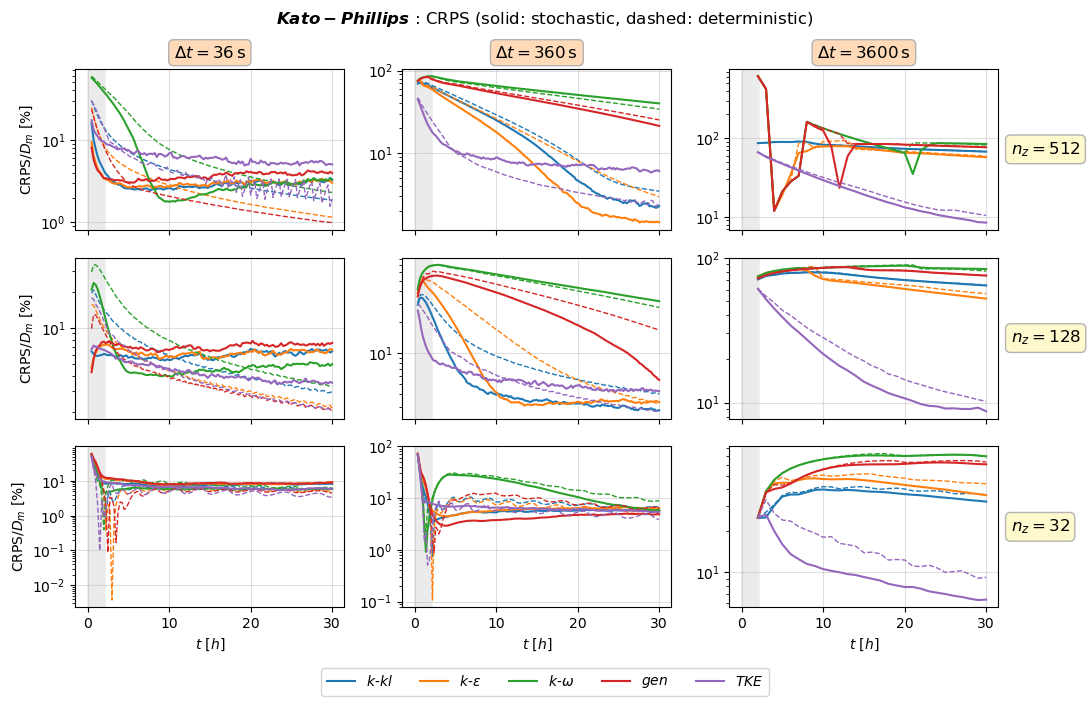

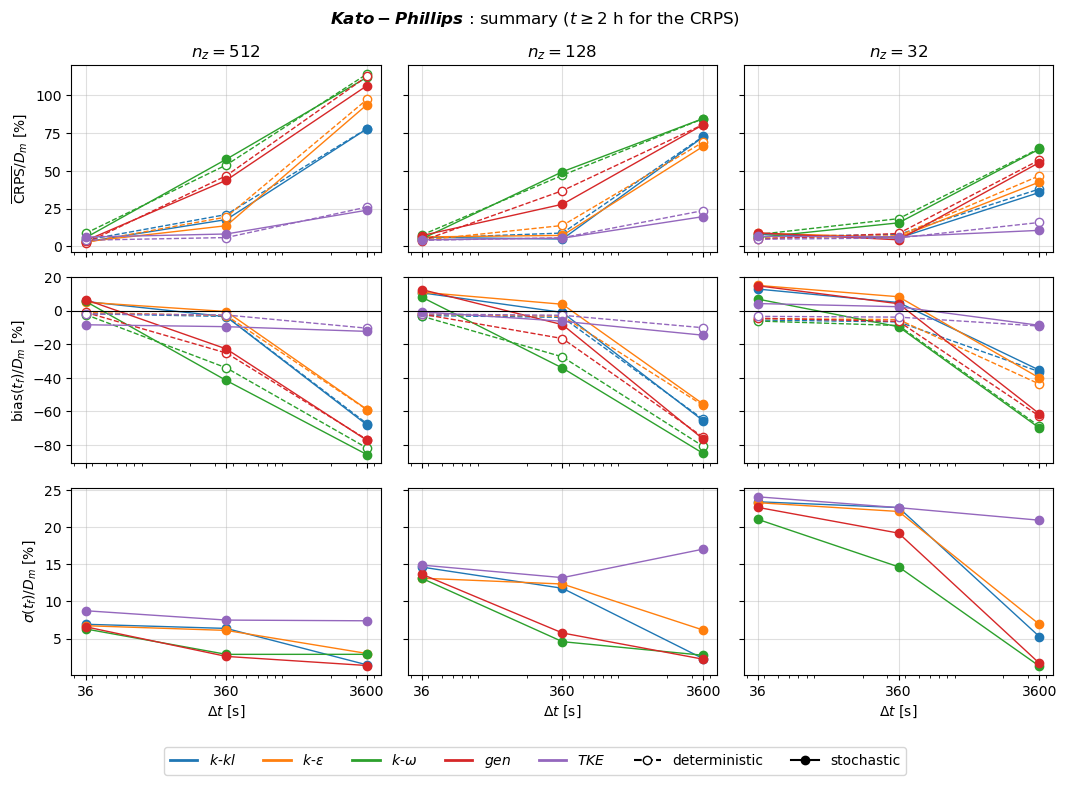

In [10]:

STO_FILE = "{out}/stochastic/{key}_dt{dt}_nz{nz}_ne500.nc"
DET_FILE = "{out}/deterministic/{key}_dt{dt}_nz{nz}_ne1.nc"     # <- adapt to your file names
T_MIN    = 2.0     # h, MLD diagnostic not meaningful before the layer has formed

def load_mld(kind, key, dt, nz):
    """Returns t [h], MLD mean [m], MLD variance [m2], reference D_m [m], depths positive."""
    fmt = STO_FILE if kind == 'sto' else DET_FILE
    _, t, m, v = get_model_variable(fmt.format(out=OUTPUT_FOLDER, key=key, dt=dt, nz=nz), "mld")
    t = np.array(t[2:], dtype=float) / 3600          # copy: never modify the loaded array
    m = np.abs(np.array(m[2:], dtype=float))
    v = np.zeros_like(m) if kind == 'det' else np.nan_to_num(np.array(v[2:], dtype=float))
    D = np.abs(ref_MLD(t * 3600))
    return t, m, v, D

METRICS = {}
for kind in ('det', 'sto'):
    for key in CLOSURES:
        for dt in DT_VALUES:
            for nz in NZ_VALUES:
                METRICS[(kind, key, dt, nz)] = kp_metrics(*load_mld(kind, key, dt, nz))


# =====================================================================
#  Figure 1: relative CRPS(t), same layout as the other figures
# =====================================================================
def draw_crps(ax, key, dt, nz):
    sto = METRICS[('sto', key, dt, nz)]
    det = METRICS[('det', key, dt, nz)]
    line, = ax.plot(sto['t'], 100 * sto['crps_t'], label=CLOSURES[key])
    ax.plot(det['t'], 100 * det['crps_t'], '--', lw=1, color=line.get_color())
    ax.axvspan(0, T_MIN, color='0.92', zorder=0)
    ax.set_yscale('log')

plot_grid(draw_crps, ylabel=r"CRPS$/D_m$ [%]", title=r"$\boldsymbol{Kato-Phillips}$ : CRPS (solid: stochastic, dashed: deterministic)")


# =====================================================================
#  Figure 2: summary, one point per run
# =====================================================================
def plot_summary():
    rows = [('crps',      r"$\overline{\mathrm{CRPS}}/D_m$ [%]"),
            ('bias_tf',   r"bias$(t_f)/D_m$ [%]"),
            ('spread_tf', r"$\sigma(t_f)/D_m$ [%]")]
    fig, axes = plt.subplots(len(rows), len(NZ_VALUES), sharex=True, sharey='row',
                             figsize=(3.6 * len(NZ_VALUES), 2.6 * len(rows)), squeeze=False)
    for i, (name, ylabel) in enumerate(rows):
        for j, nz in enumerate(NZ_VALUES):
            ax = axes[i, j]
            for k, key in enumerate(CLOSURES):
                c = f'C{k}'
                for kind, ls, mfc in (('det', '--', 'white'), ('sto', '-', c)):
                    if kind == 'det' and name == 'spread_tf':
                        continue                                    # zero by construction
                    y = [100 * METRICS[(kind, key, dt, nz)][name] for dt in DT_VALUES]
                    ax.plot(DT_VALUES, y, ls=ls, marker='o', color=c, mfc=mfc, lw=1)
            ax.set_xscale('log')
            ax.set_xticks(DT_VALUES, [str(dt) for dt in DT_VALUES])
            ax.grid(True, alpha=0.4)
            if name == 'bias_tf':
                ax.axhline(0, color='k', lw=0.8)
            if i == 0:
                ax.set_title(rf'$n_z = {nz}$')
            if i == len(rows) - 1:
                ax.set_xlabel(r'$\Delta t$ [s]')
            if j == 0:
                ax.set_ylabel(ylabel)

    handles = [Line2D([], [], color=f'C{k}', lw=2, label=CLOSURES[key]) for k, key in enumerate(CLOSURES)]
    handles += [Line2D([], [], color='k', ls='--', marker='o', mfc='white', label='deterministic'),
                Line2D([], [], color='k', ls='-',  marker='o', label='stochastic')]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(r"$\boldsymbol{Kato-Phillips}$ : summary " + rf"($t \geq {T_MIN:g}$ h for the CRPS)")
    fig.tight_layout(rect=[0, 0.05, 1, 1])

plot_summary()